# Credit Scoring Model — Feature Engineering
**Project:** Credit Scoring Model for Private Debt  
**Dataset:** Credit Risk Dataset — Kaggle (laotse/credit-risk-dataset)  
**Author:** Patrick Rich Teye  

---
This notebook covers the full feature engineering phase:
1. Outlier detection and capping
2. Missing value imputation
3. Derived features (loan-to-income ratio, sector risk tier, grade encoding)
4. Categorical encoding
5. Final clean dataset ready for model training

---
*Personal project built on a public dataset. It uses no proprietary, client or employer data and does not represent the methods or views of any organisation.*

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import warnings

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('husl')
os.makedirs('../plots', exist_ok=True)

df = pd.read_csv('credit_risk_dataset.csv')
print(f"Dataset loaded: {df.shape[0]:,} rows, {df.shape[1]} columns")

Dataset loaded: 32,581 rows, 12 columns


## 1. Outlier Detection and Capping

The EDA revealed three columns with impossible or extreme values:
- `person_age`: max = 144 (impossible — data entry error)
- `person_emp_length`: max = 123 years (impossible)
- `person_income`: max = 6,000,000 (extreme outlier — will skew model)

**Strategy:** Cap outliers at realistic upper bounds rather than dropping rows. Dropping rows risks losing valid loan data. Capping preserves the record while removing the distortion.

In a private debt context, data quality flags like these would trigger a borrower file review before any credit decision.

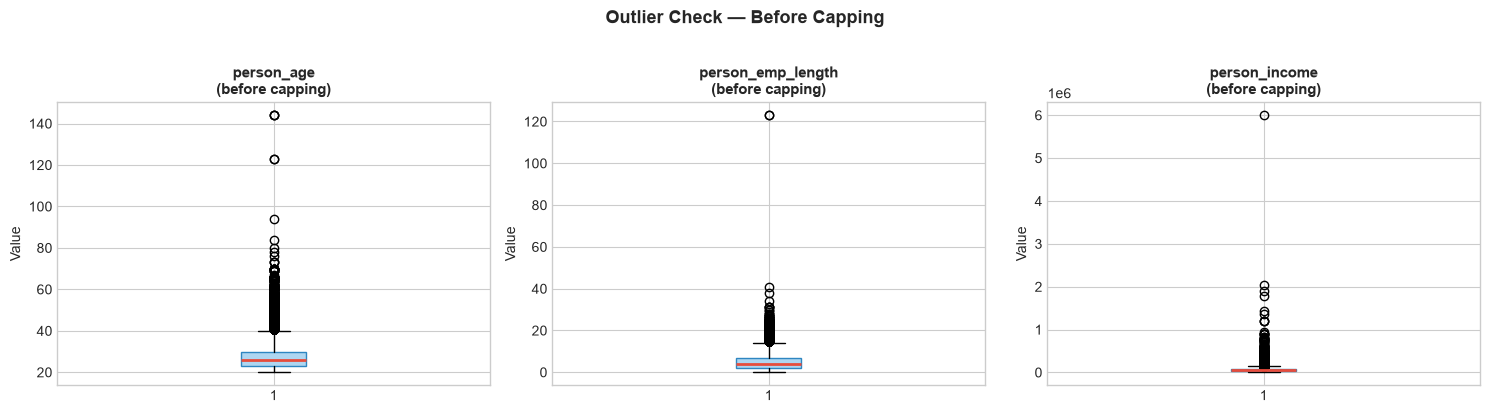

Outlier summary (before capping):
       person_age  person_emp_length  person_income
count     32581.0            31686.0        32581.0
mean         27.7                4.8        66074.8
std           6.3                4.1        61983.1
min          20.0                0.0         4000.0
25%          23.0                2.0        38500.0
50%          26.0                4.0        55000.0
75%          30.0                7.0        79200.0
max         144.0              123.0      6000000.0


In [2]:
# Visualise outliers before capping
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, col in zip(axes, ['person_age', 'person_emp_length', 'person_income']):
    ax.boxplot(df[col].dropna(), vert=True, patch_artist=True,
               boxprops=dict(facecolor='#AED6F1', color='#2E86C1'),
               medianprops=dict(color='#E74C3C', linewidth=2))
    ax.set_title(f'{col}\n(before capping)', fontsize=11, fontweight='bold')
    ax.set_ylabel('Value')

plt.suptitle('Outlier Check — Before Capping', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('../plots/outliers_before.png', dpi=150, bbox_inches='tight')
plt.show()

print("Outlier summary (before capping):")
print(df[['person_age', 'person_emp_length', 'person_income']].describe().round(1))

In [3]:
# Cap outliers at realistic upper bounds
df_clean = df.copy()

# Age: cap at 75 (reasonable maximum working age)
AGE_CAP = 75
rows_capped_age = (df_clean['person_age'] > AGE_CAP).sum()
df_clean['person_age'] = df_clean['person_age'].clip(upper=AGE_CAP)

# Employment length: cap at 40 years
EMP_CAP = 40
rows_capped_emp = (df_clean['person_emp_length'] > EMP_CAP).sum()
df_clean['person_emp_length'] = df_clean['person_emp_length'].clip(upper=EMP_CAP)

# Income: cap at 99th percentile to preserve distribution shape
income_cap = df_clean['person_income'].quantile(0.99)
rows_capped_income = (df_clean['person_income'] > income_cap).sum()
df_clean['person_income'] = df_clean['person_income'].clip(upper=income_cap)

print(f"Rows capped — person_age (>{AGE_CAP}): {rows_capped_age}")
print(f"Rows capped — person_emp_length (>{EMP_CAP}): {rows_capped_emp}")
print(f"Rows capped — person_income (>99th pct, >{income_cap:,.0f}): {rows_capped_income}")
print(f"\nTotal rows preserved: {len(df_clean):,} (no rows dropped)")

Rows capped — person_age (>75): 10
Rows capped — person_emp_length (>40): 3
Rows capped — person_income (>99th pct, >225,200): 326

Total rows preserved: 32,581 (no rows dropped)


## 2. Missing Value Imputation

Two columns have missing values (identified in EDA):
- `loan_int_rate`: 9.56% missing — impute with **median grouped by loan_grade**, since the grade directly determines the interest rate band. This is more accurate than a global median.
- `person_emp_length`: 2.75% missing — impute with **overall median** (no strong group relationship).

In [4]:
# Impute loan_int_rate using median per loan_grade
rate_by_grade = df_clean.groupby('loan_grade')['loan_int_rate'].median()
print("Median interest rate by loan grade:")
print(rate_by_grade.round(2))

df_clean['loan_int_rate'] = df_clean.apply(
    lambda row: rate_by_grade[row['loan_grade']] 
    if pd.isnull(row['loan_int_rate']) else row['loan_int_rate'],
    axis=1
)

# Impute person_emp_length with overall median
emp_median = df_clean['person_emp_length'].median()
df_clean['person_emp_length'] = df_clean['person_emp_length'].fillna(emp_median)

# Verify — no missing values should remain
remaining_missing = df_clean.isnull().sum()
print(f"\nMissing values after imputation:\n{remaining_missing[remaining_missing > 0]}")
if remaining_missing.sum() == 0:
    print("\nAll missing values resolved.")

Median interest rate by loan grade:
loan_grade
A     7.49
B    10.99
C    13.48
D    15.31
E    16.82
F    18.54
G    20.16
Name: loan_int_rate, dtype: float64



Missing values after imputation:
Series([], dtype: int64)

All missing values resolved.


## 3. Derived Features

These are the engineered features that translate raw data into meaningful credit signals. This is where domain knowledge matters — a generic analyst builds what the data gives them; a credit analyst builds what the decision requires.

**Features to create:**

| Feature | Formula | Why it matters |
|---|---|---|
| `loan_to_income` | loan_amnt / person_income | Core debt burden metric — how much of income is the loan? |
| `sector_risk_tier` | Mapped from loan_intent default rates | Groups sectors by observed risk level |
| `grade_numeric` | A=1, B=2 ... G=7 | Converts ordinal grade to usable numeric |
| `is_repeat_defaulter` | From cb_person_default_on_file | Binary flag for prior default history |
| `interest_income_ratio` | loan_int_rate / (person_income / loan_amnt * 100) | Measures interest burden relative to income |

In [5]:
# 1. Loan-to-Income Ratio
df_clean['loan_to_income'] = (df_clean['loan_amnt'] / df_clean['person_income']).round(4)

# 2. Sector Risk Tier (based on default rates from EDA)
# High: DEBTCONSOLIDATION (28.6%), MEDICAL (26.7%), HOMEIMPROVEMENT (26.1%)
# Medium: PERSONAL (19.9%), EDUCATION (17.2%)
# Low: VENTURE (14.8%)
sector_risk_map = {
    'DEBTCONSOLIDATION': 'HIGH',
    'MEDICAL':           'HIGH',
    'HOMEIMPROVEMENT':   'HIGH',
    'PERSONAL':          'MEDIUM',
    'EDUCATION':         'MEDIUM',
    'VENTURE':           'LOW'
}
df_clean['sector_risk_tier'] = df_clean['loan_intent'].map(sector_risk_map)

# 3. Grade to Numeric (A=1 is best/lowest risk, G=7 is highest risk)
grade_map = {'A': 1, 'B': 2, 'C': 3, 'D': 4, 'E': 5, 'F': 6, 'G': 7}
df_clean['grade_numeric'] = df_clean['loan_grade'].map(grade_map)

# 4. Prior Default Flag
df_clean['is_repeat_defaulter'] = (df_clean['cb_person_default_on_file'] == 'Y').astype(int)

# 5. Interest-to-Income Burden
# Annualised interest cost as % of income
df_clean['annual_interest_cost'] = df_clean['loan_amnt'] * (df_clean['loan_int_rate'] / 100)
df_clean['interest_income_ratio'] = (df_clean['annual_interest_cost'] / df_clean['person_income']).round(4)

print("New features created:")
new_features = ['loan_to_income', 'sector_risk_tier', 'grade_numeric', 'is_repeat_defaulter', 'interest_income_ratio']
print(df_clean[new_features].head(10))

New features created:
   loan_to_income sector_risk_tier  grade_numeric  is_repeat_defaulter  \
0          0.5932           MEDIUM              4                    1   
1          0.1042           MEDIUM              2                    0   
2          0.5729             HIGH              3                    0   
3          0.5344             HIGH              3                    0   
4          0.6434             HIGH              3                    1   
5          0.2525              LOW              1                    0   
6          0.4540           MEDIUM              2                    0   
7          0.4433             HIGH              2                    0   
8          0.4217           MEDIUM              1                    0   
9          0.1600              LOW              4                    0   

   interest_income_ratio  
0                 0.0950  
1                 0.0116  
2                 0.0737  
3                 0.0814  
4                 0.0918  
5

Default rate by loan-to-income band:
loan_to_income
(0.00357, 0.17]    12.5
(0.17, 0.335]      25.6
(0.335, 0.5]       70.7
(0.5, 0.665]       76.6
(0.665, 0.83]      76.2
Name: loan_status, dtype: float64

Default rate by sector risk tier:
sector_risk_tier
HIGH      27.2
LOW       14.8
MEDIUM    18.4
Name: loan_status, dtype: float64


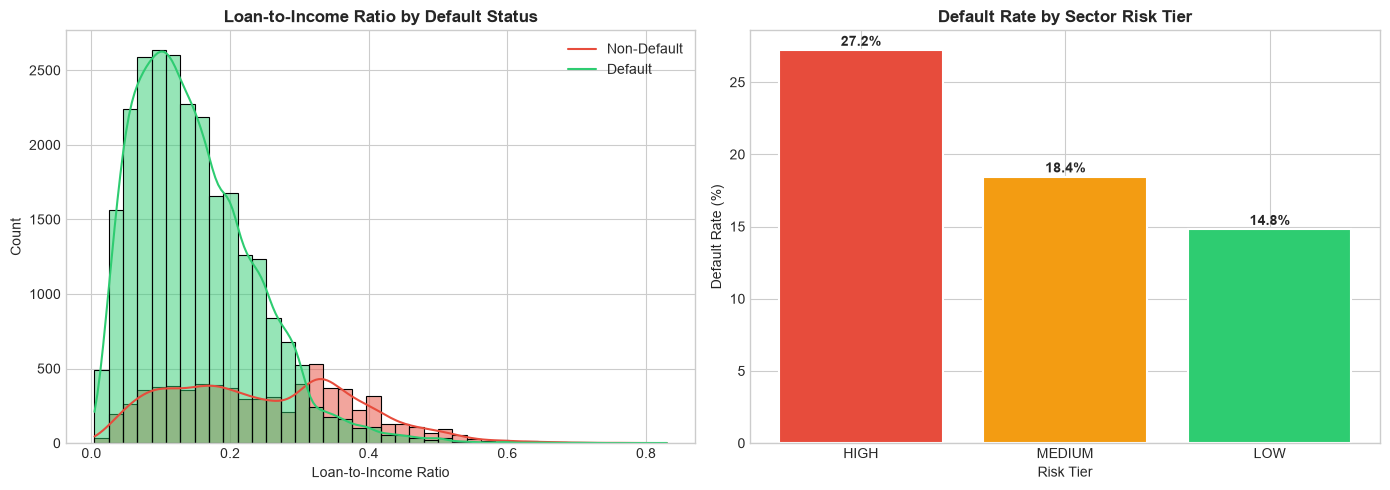

In [6]:
# Validate: check loan_to_income vs default rate
lti_default = df_clean.groupby(pd.cut(df_clean['loan_to_income'], bins=5))['loan_status'].mean() * 100
print("Default rate by loan-to-income band:")
print(lti_default.round(1))

# Validate: check sector_risk_tier vs actual default rate
tier_check = df_clean.groupby('sector_risk_tier')['loan_status'].mean() * 100
print("\nDefault rate by sector risk tier:")
print(tier_check.round(1))

# Visualise loan_to_income distribution by default status
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(data=df_clean, x='loan_to_income', hue='loan_status', 
             bins=40, kde=True, ax=axes[0],
             palette={0: '#2ecc71', 1: '#e74c3c'})
axes[0].set_title('Loan-to-Income Ratio by Default Status', fontweight='bold')
axes[0].set_xlabel('Loan-to-Income Ratio')
axes[0].legend(['Non-Default', 'Default'])

default_by_tier = df_clean.groupby('sector_risk_tier')['loan_status'].mean() * 100
default_by_tier = default_by_tier.reindex(['HIGH', 'MEDIUM', 'LOW'])
bars = axes[1].bar(default_by_tier.index, default_by_tier.values,
                   color=['#e74c3c', '#f39c12', '#2ecc71'], edgecolor='white', linewidth=1.5)
axes[1].set_title('Default Rate by Sector Risk Tier', fontweight='bold')
axes[1].set_xlabel('Risk Tier')
axes[1].set_ylabel('Default Rate (%)')
for bar, val in zip(bars, default_by_tier.values):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
                f'{val:.1f}%', ha='center', fontweight='bold')

plt.tight_layout()
plt.savefig('../plots/feature_validation.png', dpi=150, bbox_inches='tight')
plt.show()

## 4. Categorical Encoding

Convert remaining categorical columns to numeric format for model training.

- `person_home_ownership`: one-hot encode (RENT, OWN, MORTGAGE, OTHER)
- `loan_intent`: one-hot encode (or use `sector_risk_tier` — we will keep both for now)
- `sector_risk_tier`: ordinal encode (LOW=1, MEDIUM=2, HIGH=3)
- `cb_person_default_on_file`: already handled via `is_repeat_defaulter`

In [7]:
# Ordinal encode sector_risk_tier
tier_encode = {'LOW': 1, 'MEDIUM': 2, 'HIGH': 3}
df_clean['sector_risk_score'] = df_clean['sector_risk_tier'].map(tier_encode)

# One-hot encode home ownership and loan_intent
df_encoded = pd.get_dummies(df_clean, 
                             columns=['person_home_ownership', 'loan_intent'],
                             drop_first=False,
                             dtype=int)

print(f"Shape after encoding: {df_encoded.shape}")
print(f"\nNew columns added from encoding:")
new_cols = [c for c in df_encoded.columns if c not in df_clean.columns]
print(new_cols)

Shape after encoding: (32581, 27)

New columns added from encoding:
['person_home_ownership_MORTGAGE', 'person_home_ownership_OTHER', 'person_home_ownership_OWN', 'person_home_ownership_RENT', 'loan_intent_DEBTCONSOLIDATION', 'loan_intent_EDUCATION', 'loan_intent_HOMEIMPROVEMENT', 'loan_intent_MEDICAL', 'loan_intent_PERSONAL', 'loan_intent_VENTURE']


## 5. Final Clean Dataset

Select the final feature set for model training. Drop raw columns that have been replaced by engineered features, and remove columns that would not be available at the point of credit assessment.

In [8]:
# Define final feature set
# Drop: raw categorical columns replaced by encoded versions
# Drop: cb_person_default_on_file (replaced by is_repeat_defaulter)
# Drop: loan_grade (replaced by grade_numeric)
# Drop: sector_risk_tier string (replaced by sector_risk_score)
# Drop: annual_interest_cost (intermediate calculation, not a feature)

cols_to_drop = ['loan_grade', 'cb_person_default_on_file', 
                'sector_risk_tier', 'annual_interest_cost']

df_final = df_encoded.drop(columns=cols_to_drop)

# Separate features and target
X = df_final.drop(columns=['loan_status'])
y = df_final['loan_status']

print(f"Final feature set: {X.shape[1]} features, {X.shape[0]:,} rows")
print(f"Target distribution: {y.value_counts().to_dict()}")
print(f"\nFeatures going into the model:")
for i, col in enumerate(X.columns, 1):
    print(f"  {i:2}. {col}")

Final feature set: 22 features, 32,581 rows
Target distribution: {0: 25473, 1: 7108}

Features going into the model:
   1. person_age
   2. person_income
   3. person_emp_length
   4. loan_amnt
   5. loan_int_rate
   6. loan_percent_income
   7. cb_person_cred_hist_length
   8. loan_to_income
   9. grade_numeric
  10. is_repeat_defaulter
  11. interest_income_ratio
  12. sector_risk_score
  13. person_home_ownership_MORTGAGE
  14. person_home_ownership_OTHER
  15. person_home_ownership_OWN
  16. person_home_ownership_RENT
  17. loan_intent_DEBTCONSOLIDATION
  18. loan_intent_EDUCATION
  19. loan_intent_HOMEIMPROVEMENT
  20. loan_intent_MEDICAL
  21. loan_intent_PERSONAL
  22. loan_intent_VENTURE


In [9]:
# Save the clean, engineered dataset for use in model training
df_final.to_csv('credit_data_engineered.csv', index=False)
print("Clean dataset saved to credit_data_engineered.csv")
print(f"Shape: {df_final.shape}")
print(f"\nReady for model training (Mon Wk2 continuation / Thu Wk2).")

Clean dataset saved to credit_data_engineered.csv
Shape: (32581, 23)

Ready for model training (Mon Wk2 continuation / Thu Wk2).


## 6. Feature Engineering Summary

| Step | Action | Result |
|---|---|---|
| Outlier capping | Capped age (>75), employment (>40), income (>99th pct) | All rows preserved, extremes removed |
| Missing value imputation | loan_int_rate by grade median, emp_length by overall median | Zero missing values remaining |
| Loan-to-income ratio | loan_amnt / person_income | Core debt burden signal |
| Sector risk tier | Mapped from EDA default rates | HIGH / MEDIUM / LOW risk grouping |
| Grade numeric | A=1 through G=7 | Ordinal credit grade signal |
| Repeat defaulter flag | From credit bureau field | Binary prior default indicator |
| Interest-income ratio | Annual interest cost / income | Interest burden signal |
| Categorical encoding | One-hot for home ownership + intent, ordinal for risk tier | All features numeric |

---
**Next session (Thu Wk2):** Build the model — logistic regression baseline + random forest. Evaluate both.